<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/fyp_171026_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia _Dataset(5).csv'))
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,White,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,White,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,Black,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,White,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,Black,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707


### Preprocessing

In [3]:
df = df.drop(columns = ['Tired'])

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [13]:
def prep_func(df):
  """ Provide the dataframe and outputs appropriately splitted data.
      Target here assumed binary diagnosis.
      imputer assumed to be KNN"""
  #filter into X and y then train test split then num and cat
  X = df.drop(columns = ['Diagnosis'])
  y = df['Diagnosis']

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)
  X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=23)

  #y is categorical
  num_cols = X.select_dtypes(include = ['number']).columns
  cat_cols = X.select_dtypes(exclude = ['number']).columns

  #create sub pipelines for numerical (to scale) and categorical (to encode)
  #simple imputer... KNN assumes 5 clusters... clustering unknown
  num_prep_pipe = Pipeline(steps = [
      ('imputer', SimpleImputer()),
      ('scaler', StandardScaler())])

  #imputer must be median... no mean of cat
  #ohe selected because max nunique is 2 and only 3 catcols... no dimensionality curse
  cat_prep_pipe = Pipeline(steps = [
      ('imputer', SimpleImputer(strategy='most_frequent')),
      ('encoder', OneHotEncoder(sparse_output=False))])

  #column transformer fuses 'side by side'
  prep_pipe = ColumnTransformer(transformers = [
      ('num_prep', num_prep_pipe, num_cols),
      ('cat_prep', cat_prep_pipe, cat_cols)]).set_output(transform  = 'pandas')

  X_trained = prep_pipe.fit_transform(X_train)
  X_tested = prep_pipe.transform(X_test)
  X_val_prepped = prep_pipe.transform(X_val)

  return X_trained, X_tested, X_val_prepped, y_train, y_test, y_val

In [10]:
#test run of func
#prep_func(df)

### Vanilla NN

In [6]:
from sklearn.metrics import accuracy_score
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
def vanilla_NN_func(df, input_cols):
  """Creates a vanilla NN.
     input_cols becomes relevant when matrices multiplied... EXPLAIN WHEN
     This param will be reduced consistently to monitor accuracy pattern with less of them.
     100 neurons between layers."""

  #acquire split data from prep func to convert to tensors
  #validation data added
  X_trained = prep_func(df)[0]
  X_tested = prep_func(df)[1]
  X_val_prepped = prep_func(df)[2]
  y_trained = prep_func(df)[3]
  y_tested = prep_func(df)[4]
  y_val = prep_func(df)[5]

  #define the network
  X_train_tensor = torch.tensor(np.array(X_trained), dtype = torch.float32)
  X_test_tensor = torch.tensor(np.array(X_tested), dtype = torch.float32)
  X_val_tensor = torch.tensor(np.array(X_val_prepped), dtype = torch.float32)
  y_train_tensor = torch.tensor(np.array(y_trained), dtype = torch.long)
  y_test_tensor = torch.tensor(np.array(y_tested), dtype = torch.long)
  y_val_tensor = torch.tensor(np.array(y_val), dtype = torch.long)

  #custom NNs more flexible with pytorch --> add custom later
  #call pytorch neural networks parent class
  class NeuralNetwork0(nn.Module):
    #initialize variables
    def __init__(self):
      #nitialise parent module using super
      super().__init__()
      self.fc1 = nn.Linear(input_cols, 100)
      self.relu1 = nn.ReLU()
      self.fc2 = nn.Linear(100, 2)
      self.output = nn.Sigmoid()

    #generate predictions from given data
    def forward(self, x):
      x = self.fc1(x)
      x = self.relu1(x)
      x = self.fc2(x)
      x = self.output(x)
      return x

  #instantiate the model
  model = NeuralNetwork0()

  #cross entropy loss standard for binary classification
  loss_func = nn.CrossEntropyLoss()
  opt = optim.Adam(model.parameters(), lr=0.01)
  #number of epochs
  num_epochs = 100

  losses_list = []
  val_loss_list = []

  for epoch in range(num_epochs):
    #set gradients to zero ...
    opt.zero_grad()
    #forward pass
    outputs = model(X_test_tensor)
    loss = loss_func(outputs, y_test_tensor)
    #backwards propagation
    loss.backward()
    #use optimizer... here, Adam
    opt.step()
    losses_list.append(loss.item())
    val_hat = model(X_val_tensor)
    val_loss_list.append(loss_func(val_hat, y_val_tensor).detach().numpy())
  print(val_hat.dtype)

  return (losses_list), val_loss_list, outputs, y_test_tensor

vanilla_NN_func(df, input_cols= 31)

torch.float32


([0.6859360337257385,
  0.6422756314277649,
  0.6028760671615601,
  0.5651493668556213,
  0.5293010473251343,
  0.49700358510017395,
  0.46988645195961,
  0.4485996961593628,
  0.43281289935112,
  0.4215608835220337,
  0.413618803024292,
  0.4078978896141052,
  0.4035707116127014,
  0.40009957551956177,
  0.39716899394989014,
  0.3946309983730316,
  0.3924192488193512,
  0.3905031085014343,
  0.38882768154144287,
  0.3873237371444702,
  0.3859400451183319,
  0.3846224546432495,
  0.38334566354751587,
  0.3821012079715729,
  0.3809093236923218,
  0.37978193163871765,
  0.37873727083206177,
  0.3777732253074646,
  0.37685707211494446,
  0.3759394884109497,
  0.37498754262924194,
  0.3739907145500183,
  0.3729596734046936,
  0.3719135820865631,
  0.37087273597717285,
  0.3698554039001465,
  0.36886894702911377,
  0.36790841817855835,
  0.36696818470954895,
  0.3660432994365692,
  0.36513465642929077,
  0.36426010727882385,
  0.36342066526412964,
  0.3626205623149872,
  0.3618612587451935,

Visualising progress

In [106]:
def loss_plot(df, cols_to_drop, input_cols, alpha, label = '', color = 'indianred'):
  loss_to_plot = vanilla_NN_func(df.drop(columns = cols_to_drop), input_cols =input_cols)[0]
  val_loss_to_plot = vanilla_NN_func(df.drop(columns = cols_to_drop), input_cols = input_cols)[1]

  #plot tracker, list with 31 el remove after each plot.. how ???

  plt.title(f'NNs:  Loss Function over 100 Epochs') #with {} Columns')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.grid(alpha = 0.35)
  plt.plot(pd.Series(loss_to_plot), label = label, color = 'red', alpha = alpha)
  plt.plot(pd.Series(val_loss_to_plot), label='Vanilla NN Val Loss', color = 'hotpink', alpha = alpha)
  plt.legend()

torch.float32
torch.float32


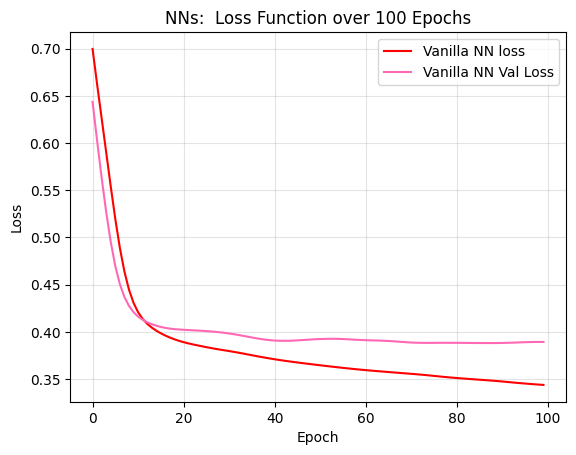

In [107]:
loss_plot(df, cols_to_drop=['Race'], input_cols=27, alpha = 1, label = 'Vanilla NN loss',color = 'indianred')

BIN

---

add clustering